# HA2 Specificity from a semantic network

| Team member | Role |
| --- | --- |
| Nikolay Evdokimov | Feature lead |
| Aleksandr Mandrov | Computation lead |
| Ivan Tsarikov | Sceptic |
| Egor Antonov | Data checker |

The original team reviewed the initial network. AI assisted with the revision, source checks and comparison experiments.

## Task 1. Build and validate the network

We keep all twenty Emotion concepts and their noun senses from HA0/HW1. Five WordNet categories connect them: entity, abstraction, attribute, psychological feature and symptom.

`is_a` arrows point **parent → child**. Each stored edge is a verified WordNet hypernym path; intermediate categories outside these 25 nodes are collapsed. Counts therefore describe this compact graph, not full WordNet depth. Symptom-related nouns fall under psychological feature in this WordNet hierarchy; this is a lexical organization, not a claim that injuries are psychological events.

`associated_with` is an illustrative co-occurrence, stored once; its arrow records source → target, without causality. `metaphorical_source_for` points from a literal source concept to an emotional target in an authored example. These context links are marked seed/generated and never enter S.

The baseline deliberately withholds the known symptom → scar edge to model a missing annotation. Scar remains visible with unavailable specificity. The additions restore it, add emotion → panic as an ancestor shortcut, and add one association. The shortcut is not a second immediate hypernym in WordNet.

In [1]:
import hashlib
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from IPython.display import display

%matplotlib inline

In [2]:
base = Path.cwd()
data_dir = base / 'data'
results_dir = base / 'results'
results_dir.mkdir(exist_ok=True)
concepts = pd.read_csv(data_dir / 'concepts.csv', keep_default_na=False)
edges = pd.read_csv(base / 'edges.csv', keep_default_na=False)
operations = pd.read_csv(data_dir / 'perturbations.csv', keep_default_na=False)
ha0 = pd.read_csv(data_dir / 'HA0_Emotion.csv', sep=';', encoding='utf-8-sig')
ROOT = 'entity'
assert len(concepts) == 25 and concepts['id'].is_unique
assert set(concepts.loc[concepts['origin'].eq('HA0 Emotion inventory'), 'id']) == set(ha0['term'])
assert concepts['pos'].eq('n').all()
assert not edges[['source', 'target', 'type']].duplicated().any()
assert set(edges['source']) | set(edges['target']) <= set(concepts['id'])
assert len(set(edges['type'])) >= 3
assert edges['provenance'].ne('').all() and edges['evidence'].ne('').all()
print(f"Inventory: {len(ha0)} original concepts + {len(concepts)-len(ha0)} supporting categories")
display(
    edges.groupby(['type', 'provenance', 'annotation_origin']).size().rename('count').reset_index()
)

,type,provenance,annotation_origin,count
0,associated_with,seed,generated,2
1,is_a,wordnet,sourced,23
2,metaphorical_source_for,seed,generated,2


### Verify the taxonomy against WordNet

The bundled noun data are checked by hash. Every step of each category path must be a real direct hypernym relation. Definitions and senses of the original twenty concepts must match revised HA0.

In [3]:
with zipfile.ZipFile(data_dir / 'wordnet.zip') as archive:
    noun_data = archive.read('wordnet/data.noun')
assert (
    hashlib.sha256(noun_data).hexdigest()
    == '489f145e0f68877c0be5bd0eb4117adaaac52f38f6204eb8d85dbe2158b614cc'
)
wordnet_parents = {}
wordnet_glosses = {}
wordnet_lemmas = {}
for line in noun_data.decode().splitlines():
    if not line or not line[0].isdigit():
        continue
    fields, gloss = line.split('|', 1)
    f = fields.split()
    count = int(f[3], 16)
    i = 4 + 2 * count
    pointers = int(f[i])
    i += 1
    wordnet_parents[f[0]] = []
    wordnet_glosses[f[0]] = gloss.strip().split('; "')[0]
    wordnet_lemmas[f[0]] = f[4 : 4 + 2 * count : 2]
    for j in range(pointers):
        symbol, offset, pos, _ = f[i + 4 * j : i + 4 * j + 4]
        if symbol in ('@', '@i') and pos == 'n':
            wordnet_parents[f[0]].append(offset)

In [4]:
offsets = concepts.set_index('id')['wordnet_synset'].str.split('-').str[1].to_dict()
for row in concepts.itertuples(index=False):
    assert row.id in wordnet_lemmas[offsets[row.id]]
    if row.origin == 'supporting category':
        assert row.definition == wordnet_glosses[offsets[row.id]]
for row in ha0.itertuples(index=False):
    selected = concepts.set_index('id').loc[row.term]
    assert selected['wordnet_synset'] == row.wordnet_synset
    assert selected['definition'] == row.definition

for row in pd.concat([edges, operations]).itertuples(index=False):
    if row.type != 'is_a':
        continue
    path = row.evidence.split(' > ')
    assert path[0] == offsets[row.source] and path[-1] == offsets[row.target]
    assert len(path) - 1 == int(row.wordnet_hops)
    for parent, child in zip(path, path[1:]):
        assert parent in wordnet_parents[child], (parent, child)
print('All category paths verified against WordNet 3.0.')

## Task 2. Estimate and compare specificity

The typed network is a MultiDiGraph so two relations between the same nodes can coexist. Its `is_a` layer is a DAG directed parent → child.

For reachable noun nodes, let d_min and d_max be the shortest and longest root-path lengths. Let D be the maximum d_min, and M the maximum number of reachable descendants. We use:

- S_depth = d_min / D. The alternative-parent range is [d_min / D, d_max / D].
- S_breadth = 1 − log(1 + descendants) / log(1 + M).

These are the formulas in lecture slides 9–10 and the instructor notebook. Both raw and normalized values are retained. The denominator of the displayed path range is the same D; a longest-path endpoint can exceed one in another DAG. Disconnected nodes have NA scores, not zero. Denominators are recalculated in each graph; comparisons also hold the baseline denominators fixed to reveal normalization effects.

In [5]:
node_ids = concepts['id'].tolist()
labels = concepts.set_index('id')['label'].to_dict()


def graph_views(edge_table):
    full = nx.MultiDiGraph()
    taxonomy = nx.DiGraph()
    full.add_nodes_from(node_ids)
    taxonomy.add_nodes_from(node_ids)
    for row in edge_table.to_dict('records'):
        attrs = {k: v for k, v in row.items() if k not in ['source', 'target']}
        full.add_edge(row['source'], row['target'], key=row['type'], **attrs)
        if row['type'] == 'is_a':
            taxonomy.add_edge(row['source'], row['target'])
    assert nx.is_directed_acyclic_graph(taxonomy)
    return full, taxonomy

In [6]:
def specificity_table(edge_table, fixed_denominators=None):
    full, taxonomy = graph_views(edge_table)
    shortest = dict(nx.single_source_shortest_path_length(taxonomy, ROOT))
    longest = {ROOT: 0}
    path_counts = {ROOT: 1}
    for node in nx.topological_sort(taxonomy):
        if node == ROOT or node not in shortest:
            continue
        parents = [p for p in taxonomy.predecessors(node) if p in longest]
        longest[node] = 1 + max(longest[p] for p in parents)
        path_counts[node] = sum(path_counts[p] for p in parents)
    descendant_counts = {n: len(nx.descendants(taxonomy, n)) for n in node_ids}
    D = max(shortest.values())
    M = max(descendant_counts[n] for n in shortest)
    if fixed_denominators is not None:
        D, M = fixed_denominators
    assert D > 0 and M > 0
    rows = []
    for node in node_ids:
        reachable = node in shortest
        parents = sorted(taxonomy.predecessors(node))
        rows.append(
            {
                'id': node,
                'reachable': reachable,
                'parents': '; '.join(parents),
                'parent_count': len(parents),
                'root_path_count': path_counts.get(node, 0),
                'depth_min': shortest.get(node, np.nan),
                'depth_max': longest.get(node, np.nan),
                'descendants': descendant_counts[node],
                'S_depth': shortest[node] / D if reachable else np.nan,
                'S_depth_max': longest[node] / D if reachable else np.nan,
                'S_breadth': (
                    1 - np.log1p(descendant_counts[node]) / np.log1p(M) if reachable else np.nan
                ),
                'taxonomy_in_degree': taxonomy.in_degree(node),
                'taxonomy_out_degree': taxonomy.out_degree(node),
                'typed_degree': full.degree(node),
                'normalizer_depth': D,
                'normalizer_descendants': M,
            }
        )
    return pd.DataFrame(rows)

In [7]:
_, baseline_taxonomy = graph_views(edges)
baseline = specificity_table(edges)
assert baseline.loc[~baseline['reachable'], 'id'].tolist() == ['scar']
nodes = concepts.merge(baseline, on='id', validate='one_to_one')
node_export = nodes.rename(columns={'label': 'concept', 'depth_min': 'depth'})
first_columns = ['concept', 'parents', 'depth']
node_export = node_export[
    first_columns + [c for c in node_export.columns if c not in first_columns]
]
node_export.to_csv(base / 'nodes.csv', index=False, na_rep='NA')
display(
    nodes[
        ['label', 'parents', 'depth_min', 'depth_max', 'descendants', 'S_depth', 'S_breadth']
    ].round(3)
)
print(
    'Baseline denominators:',
    int(baseline['normalizer_depth'].iloc[0]),
    int(baseline['normalizer_descendants'].iloc[0]),
)

,label,parents,depth_min,depth_max,descendants,S_depth,S_breadth
0,emotion,feeling,4.0,4.0,7,0.667,0.346
1,feeling,attribute,3.0,3.0,12,0.500,0.193
2,mood,feeling,4.0,4.0,0,0.667,1.000
3,fear,emotion,5.0,5.0,1,0.833,0.782
4,anger,emotion,5.0,5.0,1,0.833,0.782
5,disgust,feeling,4.0,4.0,0,0.667,1.000
6,joy,emotion,5.0,5.0,0,0.833,1.000
7,sadness,feeling,4.0,4.0,0,0.667,1.000
8,panic,fear,6.0,6.0,0,1.000,1.000
9,nausea,symptom,4.0,4.0,0,0.667,1.000


### Hierarchical visualization

Positions use taxonomy depth and a fixed branch order, following the instructor notebook's layered-layout fallback. The same positions are retained for perturbation plots. Context links are shown in a separate panel with repeated node labels to avoid crossing the hierarchy. Grey marks nodes without a root path.

In [8]:
supporting = set(concepts.loc[concepts['origin'].eq('supporting category'), 'id'])
layers = {
    0: ['entity'],
    1: ['abstraction', 'flood'],
    2: ['attribute', 'psychological_feature'],
    3: ['feeling', 'heaviness', 'symptom', 'warmth', 'freeze'],
    4: ['mood', 'disgust', 'sadness', 'nostalgia', 'emotion', 'nausea', 'sting'],
    5: ['fear', 'anger', 'joy', 'anxiety', 'resentment'],
    6: ['panic', 'rage'],
}
# Tailor horizontal spacing to the branch structure; vertical position is depth.
x_locations = {
    'entity': 0.0,
    'abstraction': 0.0,
    'flood': 7.5,
    'attribute': -3.5,
    'psychological_feature': 4.0,
    'feeling': -4.5,
    'heaviness': -0.6,
    'symptom': 3.0,
    'warmth': 5.7,
    'freeze': 8.2,
    'mood': -8.2,
    'disgust': -5.7,
    'sadness': -3.2,
    'nostalgia': -0.7,
    'emotion': -3.2,
    'nausea': 3.0,
    'sting': 5.7,
    'fear': -8.2,
    'anger': -5.7,
    'joy': -3.2,
    'anxiety': -0.7,
    'resentment': 1.8,
    'panic': -8.2,
    'rage': -5.7,
}
# Spread the broad emotion node into a gap below feeling, without overlapping peers.
x_locations['emotion'] = -9.8
positions = {n: (x_locations[n], -depth * 1.65) for depth, ns in layers.items() for n in ns}
positions['scar'] = (8.2, -4 * 1.65)
assert set(positions) == set(node_ids)
assert all(positions[u][1] > positions[v][1] for u, v in baseline_taxonomy.edges())

In [9]:
def draw_context_links(edge_table, context_ax):
    context_rows = edge_table.loc[edge_table['type'].ne('is_a')]
    context_colors = {'associated_with': '#BC6C25', 'metaphorical_source_for': '#7A5195'}
    context_names = {
        'associated_with': 'ASSOCIATED-WITH',
        'metaphorical_source_for': 'METAPHORICAL-SOURCE-FOR',
    }
    for i, row in enumerate(context_rows.itertuples(index=False)):
        y = -i * 1.15
        color = context_colors[row.type]
        context_ax.text(
            0.5, y + 0.28, context_names[row.type], ha='center', fontsize=10, color=color
        )
        for x, node in [(0, row.source), (1, row.target)]:
            context_ax.text(
                x,
                y,
                labels[node],
                ha='center',
                va='center',
                fontsize=10,
                bbox=dict(boxstyle='round,pad=0.4', facecolor='#F7F9FC', edgecolor=color),
            )
        context_ax.annotate(
            '',
            xy=(0.80, y),
            xytext=(0.20, y),
            arrowprops=dict(arrowstyle='-|>', linestyle='--', color=color, lw=1.5),
        )
    context_ax.set_title(
        'Context links\nRepeated labels refer to the same nodes', fontsize=12, pad=28
    )
    context_ax.set_xlim(-0.35, 1.35)
    context_ax.set_ylim(-7.5, 1.0)
    context_ax.axis('off')

In [10]:
def draw_network(edge_table, filename, title):
    _, taxonomy = graph_views(edge_table)
    reachable = {ROOT} | nx.descendants(taxonomy, ROOT)
    fig, (ax, context_ax) = plt.subplots(
        1, 2, figsize=(24, 13), gridspec_kw={'width_ratios': [3.3, 1]}
    )
    is_a = [(r.source, r.target) for r in edge_table.itertuples() if r.type == 'is_a']
    nx.draw_networkx_edges(
        taxonomy,
        positions,
        edgelist=is_a,
        ax=ax,
        arrows=True,
        arrowstyle='-|>',
        arrowsize=14,
        width=1.5,
        edge_color='#556879',
        min_source_margin=24,
        min_target_margin=25,
        node_size=1700,
    )
    draw_context_links(edge_table, context_ax)

    for node, (x, y) in positions.items():
        color = (
            '#E5E7EB' if node not in reachable else '#DCE9F1' if node in supporting else '#F7F9FC'
        )
        label = labels[node].replace('psychological feature', 'psychological\nfeature')
        if node not in reachable:
            label += '\n(no root path)'
        ax.text(
            x,
            y,
            label,
            ha='center',
            va='center',
            fontsize=11,
            zorder=4,
            bbox=dict(
                boxstyle='round,pad=0.5', facecolor=color, edgecolor='#516579', linewidth=1.0
            ),
        )
    legend = [
        Line2D([0], [0], color='#556879', lw=1.6, label='IS-A: parent → child'),
        Line2D(
            [0],
            [0],
            color='#BC6C25',
            lw=1.6,
            linestyle='--',
            label='ASSOCIATED-WITH: illustrative co-occurrence',
        ),
        Line2D(
            [0],
            [0],
            color='#7A5195',
            lw=1.6,
            linestyle='--',
            label='METAPHORICAL-SOURCE-FOR: literal source → emotional target',
        ),
        Patch(facecolor='#DCE9F1', edgecolor='#516579', label='Supporting category'),
        Patch(facecolor='#E5E7EB', edgecolor='#516579', label='No root path; S unavailable'),
    ]
    ax.legend(handles=legend, loc='lower right', fontsize=10, frameon=True)
    fig.suptitle(title, fontsize=18)
    ax.text(
        0.01,
        0.98,
        '25 noun nodes · solid arrows alone determine S\nPositions show baseline levels in every panel. Shortcuts may skip levels.',
        transform=ax.transAxes,
        ha='left',
        va='top',
        fontsize=10,
        color='#425466',
    )
    ax.set_xlim(-11.6, 10.4)
    ax.set_ylim(-11.1, 1.3)
    ax.axis('off')
    fig.tight_layout()
    fig.savefig(filename, dpi=170, bbox_inches='tight')
    plt.show()

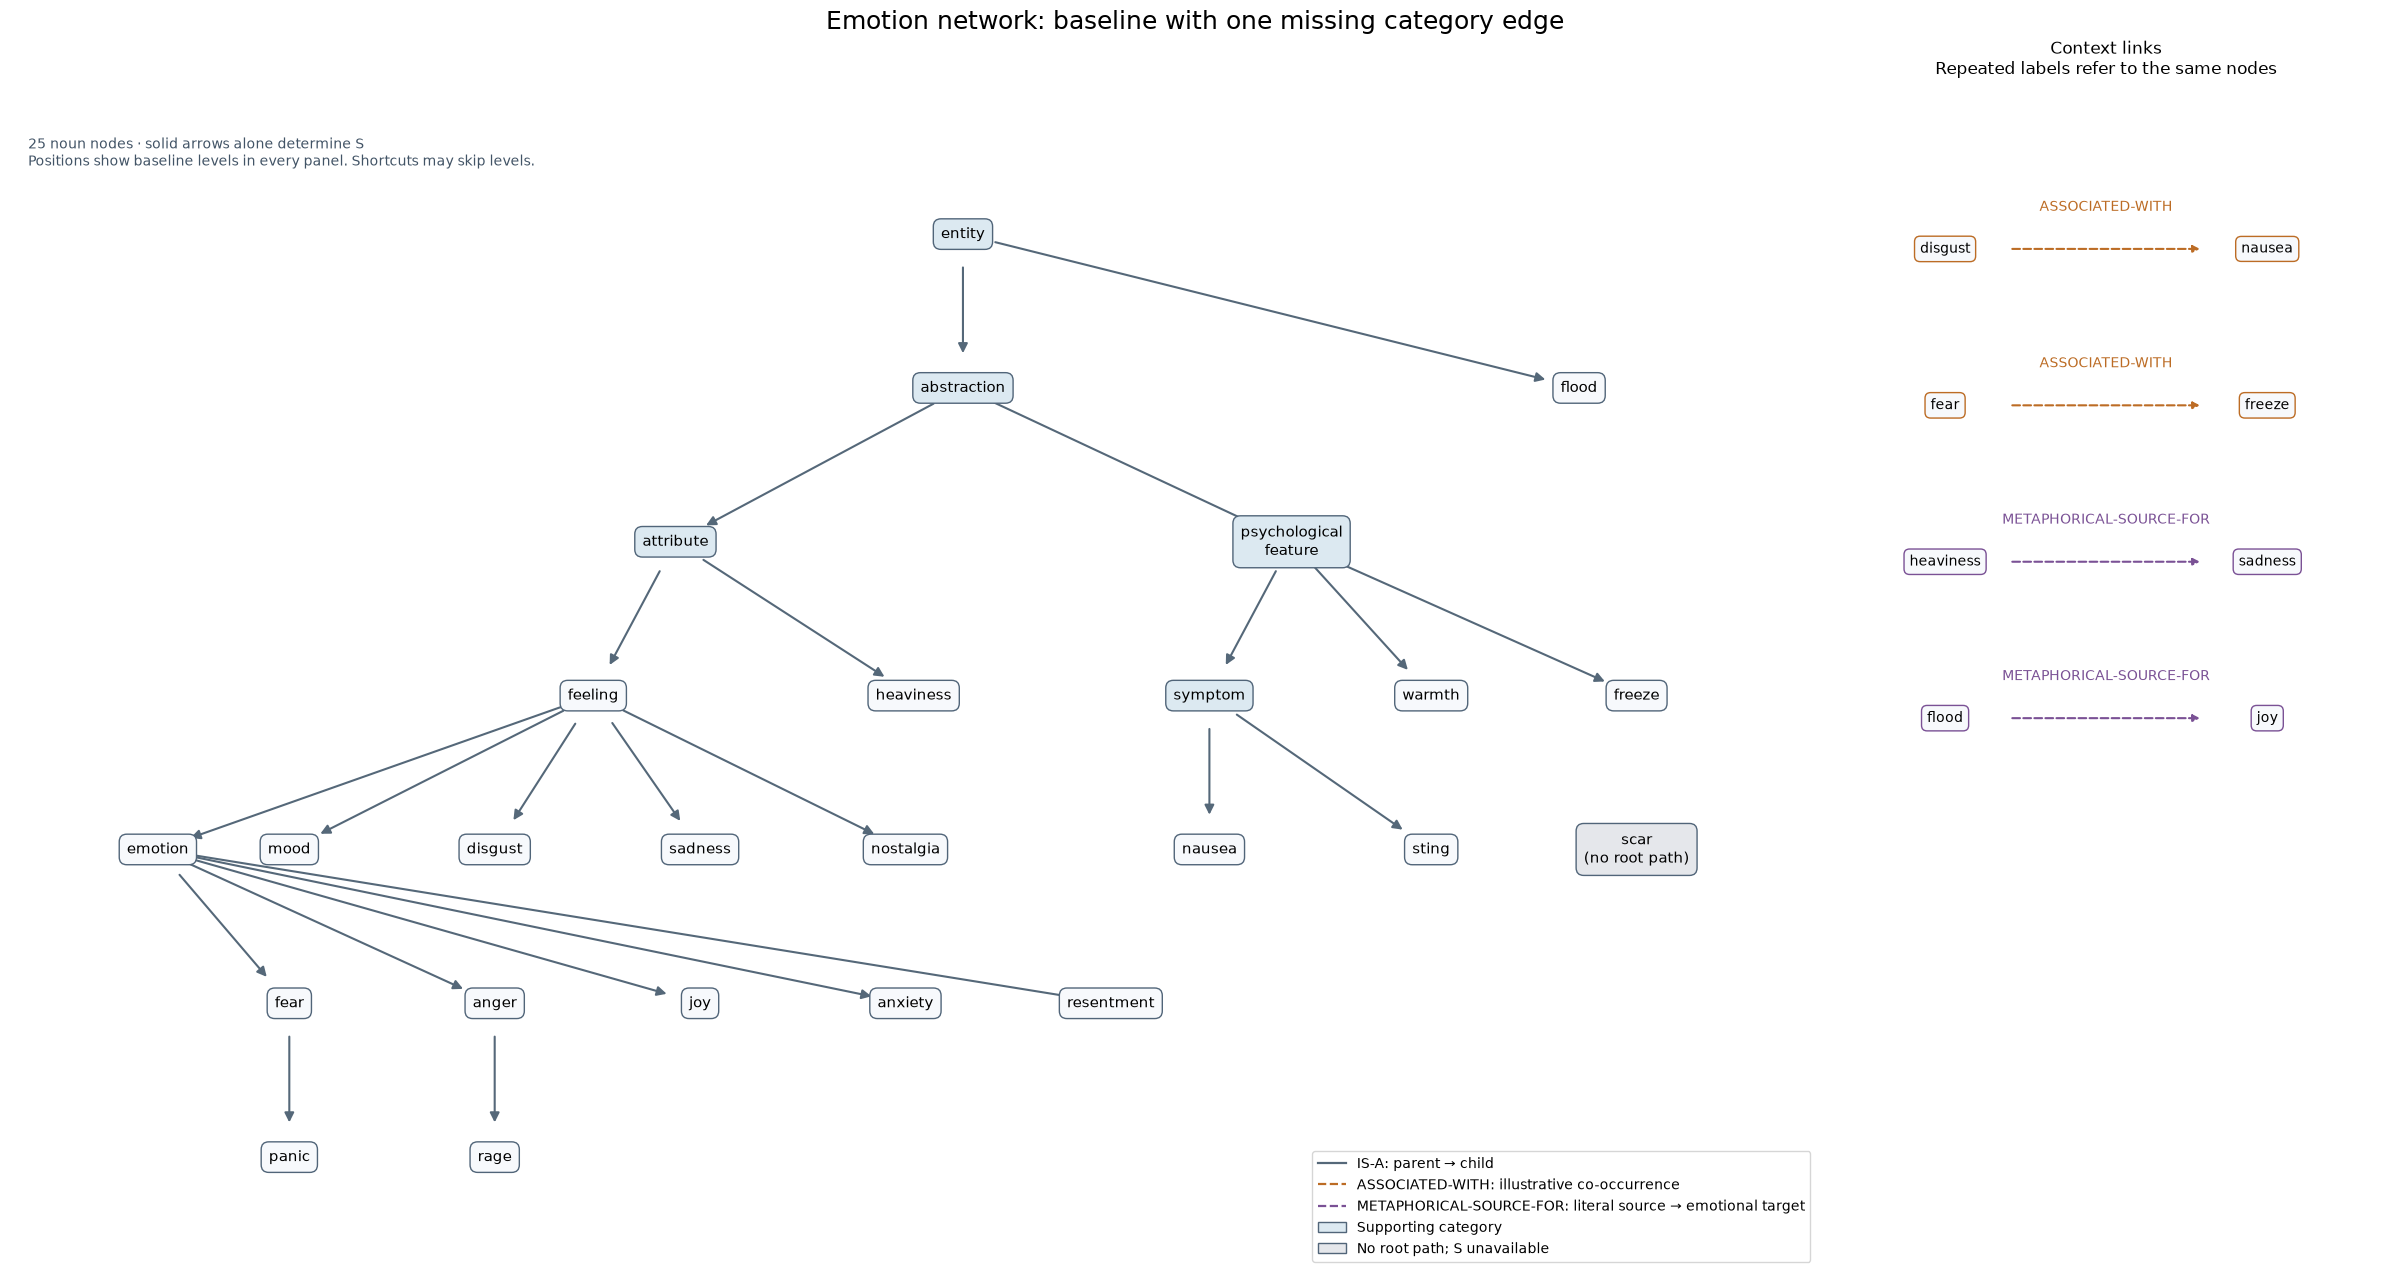

In [11]:
draw_network(
    edges, base / 'network.png', 'Emotion network: baseline with one missing category edge'
)

### Compare broad and narrow concepts

We compare three broad categories with three narrower emotional states. Descendant counts cover only represented nodes, so an unexpanded broad concept can resemble a leaf. Neither estimate is a human specificity rating.

In [12]:
comparison_ids = ['entity', 'feeling', 'emotion', 'fear', 'panic', 'rage', 'resentment']
display(
    nodes.set_index('id')
    .loc[comparison_ids, ['depth_min', 'descendants', 'S_depth', 'S_breadth']]
    .round(3)
)

,depth_min,descendants,S_depth,S_breadth
id,,,,
entity,0.0,23,0.000,0.000
feeling,3.0,12,0.500,0.193
emotion,4.0,7,0.667,0.346
fear,5.0,1,0.833,0.782
panic,6.0,0,1.000,1.000
rage,6.0,0,1.000,1.000
resentment,5.0,0,0.833,1.000


## Task 3. Perturb the network

Add symptom → scar (restore its parent), emotion → panic (a broader second parent), and anxiety → freeze (association). Then remove fear → panic (leaf edge), feeling → emotion (middle of a branch), and the added emotion → panic edge. No nodes are added or removed. All three graph versions are saved as edge CSVs.

A second parent yields alternative path lengths. The association is also checked in isolation: it must leave both S estimates unchanged. Disconnections are reported separately from numeric changes larger than 0.1.

In [13]:
add_rows = operations.loc[operations['operation'].eq('add'), edges.columns]
remove_rows = operations.loc[operations['operation'].eq('remove'), edges.columns]
assert len(add_rows) == len(remove_rows) == 3
edge_columns = ['source', 'target', 'type']
keys0 = set(map(tuple, edges[edge_columns].to_numpy()))
assert not (keys0 & set(map(tuple, add_rows[edge_columns].to_numpy())))
added_edges = pd.concat([edges, add_rows], ignore_index=True)
remove_keys = set(map(tuple, remove_rows[edge_columns].to_numpy()))
assert remove_keys <= set(map(tuple, added_edges[edge_columns].to_numpy()))
removed_edges = added_edges.loc[
    [tuple(row) not in remove_keys for row in added_edges[edge_columns].to_numpy()]
].reset_index(drop=True)
assert len(added_edges) == len(edges) + 3 and len(removed_edges) == len(edges)
added_edges.to_csv(results_dir / 'edges_added.csv', index=False)
removed_edges.to_csv(results_dir / 'edges_removed.csv', index=False)

In [14]:
tables = {
    'baseline': baseline,
    'added': specificity_table(added_edges),
    'removed': specificity_table(removed_edges),
}
fixed = (baseline['normalizer_depth'].iloc[0], baseline['normalizer_descendants'].iloc[0])
fixed_tables = {
    'baseline': baseline,
    'added': specificity_table(added_edges, fixed),
    'removed': specificity_table(removed_edges, fixed),
}
for name, table in tables.items():
    table.to_csv(results_dir / f'specificity_{name}.csv', index=False, na_rep='NA')

association_only = pd.concat(
    [edges, add_rows.loc[add_rows['type'].eq('associated_with')]], ignore_index=True
)
association_metrics = specificity_table(association_only)
pd.testing.assert_frame_equal(
    baseline[['id', 'S_depth', 'S_breadth']], association_metrics[['id', 'S_depth', 'S_breadth']]
)

multi = pd.concat([table.assign(stage=name) for name, table in tables.items()])
multi = multi.loc[multi['parent_count'].gt(1)]
multi.to_csv(results_dir / 'multiple_parents.csv', index=False)
display(
    multi[
        [
            'stage',
            'id',
            'parents',
            'root_path_count',
            'depth_min',
            'depth_max',
            'S_depth',
            'S_depth_max',
        ]
    ].round(3)
)
_, T_added = graph_views(added_edges)
print('Panic root paths after additions:')
for path in nx.all_simple_paths(T_added, ROOT, 'panic'):
    print(' → '.join(path))
print('Association-only addition: both specificity estimates unchanged.')

,stage,id,parents,root_path_count,depth_min,depth_max,S_depth,S_depth_max
8,added,panic,emotion; fear,2,5.0,6.0,0.833,1.0


In [15]:
comparisons = []
for before_name, after_name in [
    ('baseline', 'added'),
    ('added', 'removed'),
    ('baseline', 'removed'),
]:
    before = tables[before_name].set_index('id')
    after = tables[after_name].set_index('id')
    before_fixed = fixed_tables[before_name].set_index('id')
    after_fixed = fixed_tables[after_name].set_index('id')
    for node in node_ids:
        a, b = before.loc[node], after.loc[node]
        both = bool(a['reachable'] and b['reachable'])
        delta_depth = b['S_depth'] - a['S_depth'] if both else np.nan
        delta_breadth = b['S_breadth'] - a['S_breadth'] if both else np.nan
        status = (
            'connected'
            if both
            else (
                'newly reachable'
                if b['reachable']
                else 'disconnected' if a['reachable'] else 'still disconnected'
            )
        )
        causes = []
        if not both:
            if status == 'newly reachable':
                causes.append('Restoring symptom → scar creates a root path.')
            elif status == 'disconnected' and node == 'panic':
                causes.append('Both fear → panic and emotion → panic were removed.')
            elif status == 'disconnected':
                causes.append('Removing feeling → emotion disconnects this branch.')
            else:
                causes.append('No root path in either graph.')
        else:
            if a['depth_min'] != b['depth_min']:
                causes.append('Shortest root path changed.')
            if a['descendants'] != b['descendants']:
                causes.append('Reachable descendant count changed.')
            if a['normalizer_depth'] != b['normalizer_depth']:
                causes.append('Maximum depth changed.')
            if a['normalizer_descendants'] != b['normalizer_descendants']:
                causes.append('Maximum descendant count changed.')
            if not causes:
                causes.append('Taxonomic inputs and normalizers unchanged.')
        comparisons.append(
            {
                'comparison': before_name + ' → ' + after_name,
                'id': node,
                'status': status,
                'S_depth_before': a['S_depth'],
                'S_depth_after': b['S_depth'],
                'delta_S_depth': delta_depth,
                'S_breadth_before': a['S_breadth'],
                'S_breadth_after': b['S_breadth'],
                'delta_S_breadth': delta_breadth,
                'delta_depth_fixed_scale': (
                    after_fixed.loc[node, 'S_depth'] - before_fixed.loc[node, 'S_depth']
                    if both
                    else np.nan
                ),
                'delta_breadth_fixed_scale': (
                    after_fixed.loc[node, 'S_breadth'] - before_fixed.loc[node, 'S_breadth']
                    if both
                    else np.nan
                ),
                'moved_over_0_1': both
                and (abs(delta_depth) > 0.1 + 1e-12 or abs(delta_breadth) > 0.1 + 1e-12),
                'explanation': ' '.join(causes),
            }
        )

In [16]:
comparison = pd.DataFrame(comparisons)
comparison.to_csv(base / 'perturbation.csv', index=False, na_rep='NA')
important = comparison.loc[
    comparison['moved_over_0_1'] | comparison['status'].isin(['newly reachable', 'disconnected'])
]
important = important.loc[important['comparison'].isin(['baseline → added', 'added → removed'])]
display(
    important[
        ['comparison', 'id', 'status', 'delta_S_depth', 'delta_S_breadth', 'explanation']
    ].round(3)
)
summary = pd.DataFrame(
    [
        {
            'stage': name,
            'nodes': len(table),
            'reachable': int(table['reachable'].sum()),
            'max_shortest_depth': int(table['normalizer_depth'].iloc[0]),
            'max_descendants': int(table['normalizer_descendants'].iloc[0]),
        }
        for name, table in tables.items()
    ]
)
display(summary)
summary.to_csv(results_dir / 'stage_summary.csv', index=False)

,comparison,id,status,delta_S_depth,delta_S_breadth,explanation
8,baseline → added,panic,connected,-0.167,0.000,Shortest root path changed. Maximum descendant...
19,baseline → added,scar,newly reachable,NaN,NaN,Restoring symptom → scar creates a root path.
25,added → removed,emotion,disconnected,NaN,NaN,Removing feeling → emotion disconnects this br...
26,added → removed,feeling,connected,0.250,0.229,Reachable descendant count changed. Maximum de...
27,added → removed,mood,connected,0.333,0.000,Maximum depth changed. Maximum descendant coun...
28,added → removed,fear,disconnected,NaN,NaN,Removing feeling → emotion disconnects this br...
29,added → removed,anger,disconnected,NaN,NaN,Removing feeling → emotion disconnects this br...
30,added → removed,disgust,connected,0.333,0.000,Maximum depth changed. Maximum descendant coun...
31,added → removed,joy,disconnected,NaN,NaN,Removing feeling → emotion disconnects this br...
32,added → removed,sadness,connected,0.333,0.000,Maximum depth changed. Maximum descendant coun...


,stage,nodes,reachable,max_shortest_depth,max_descendants
0,baseline,25,24,6,23
1,added,25,25,6,24
2,removed,25,17,4,16


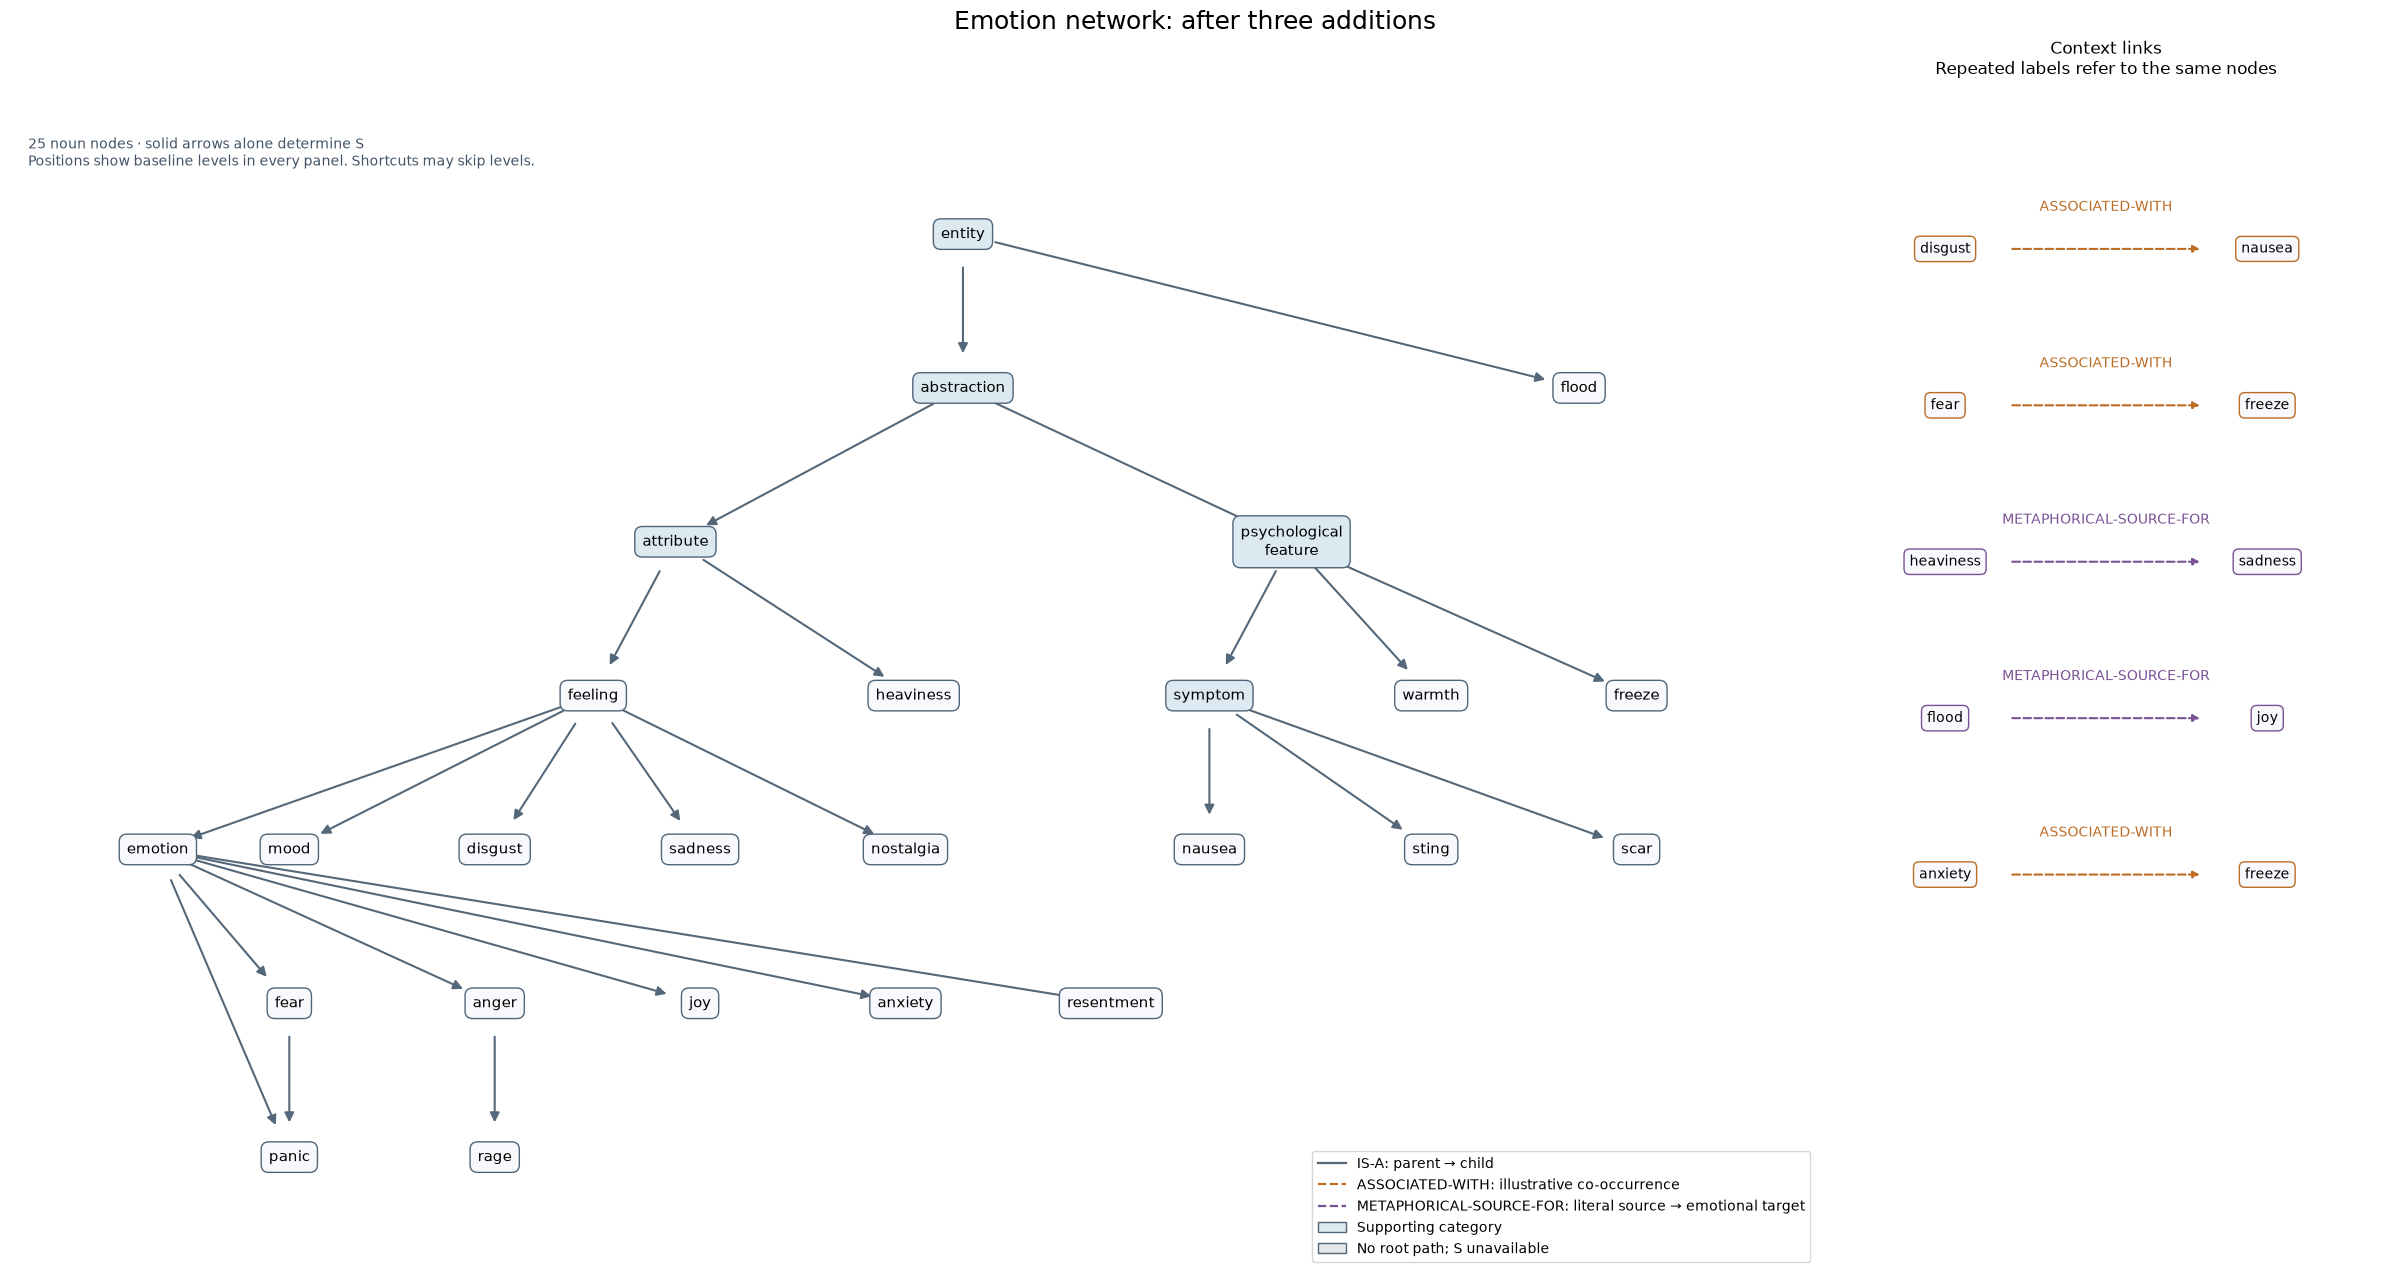

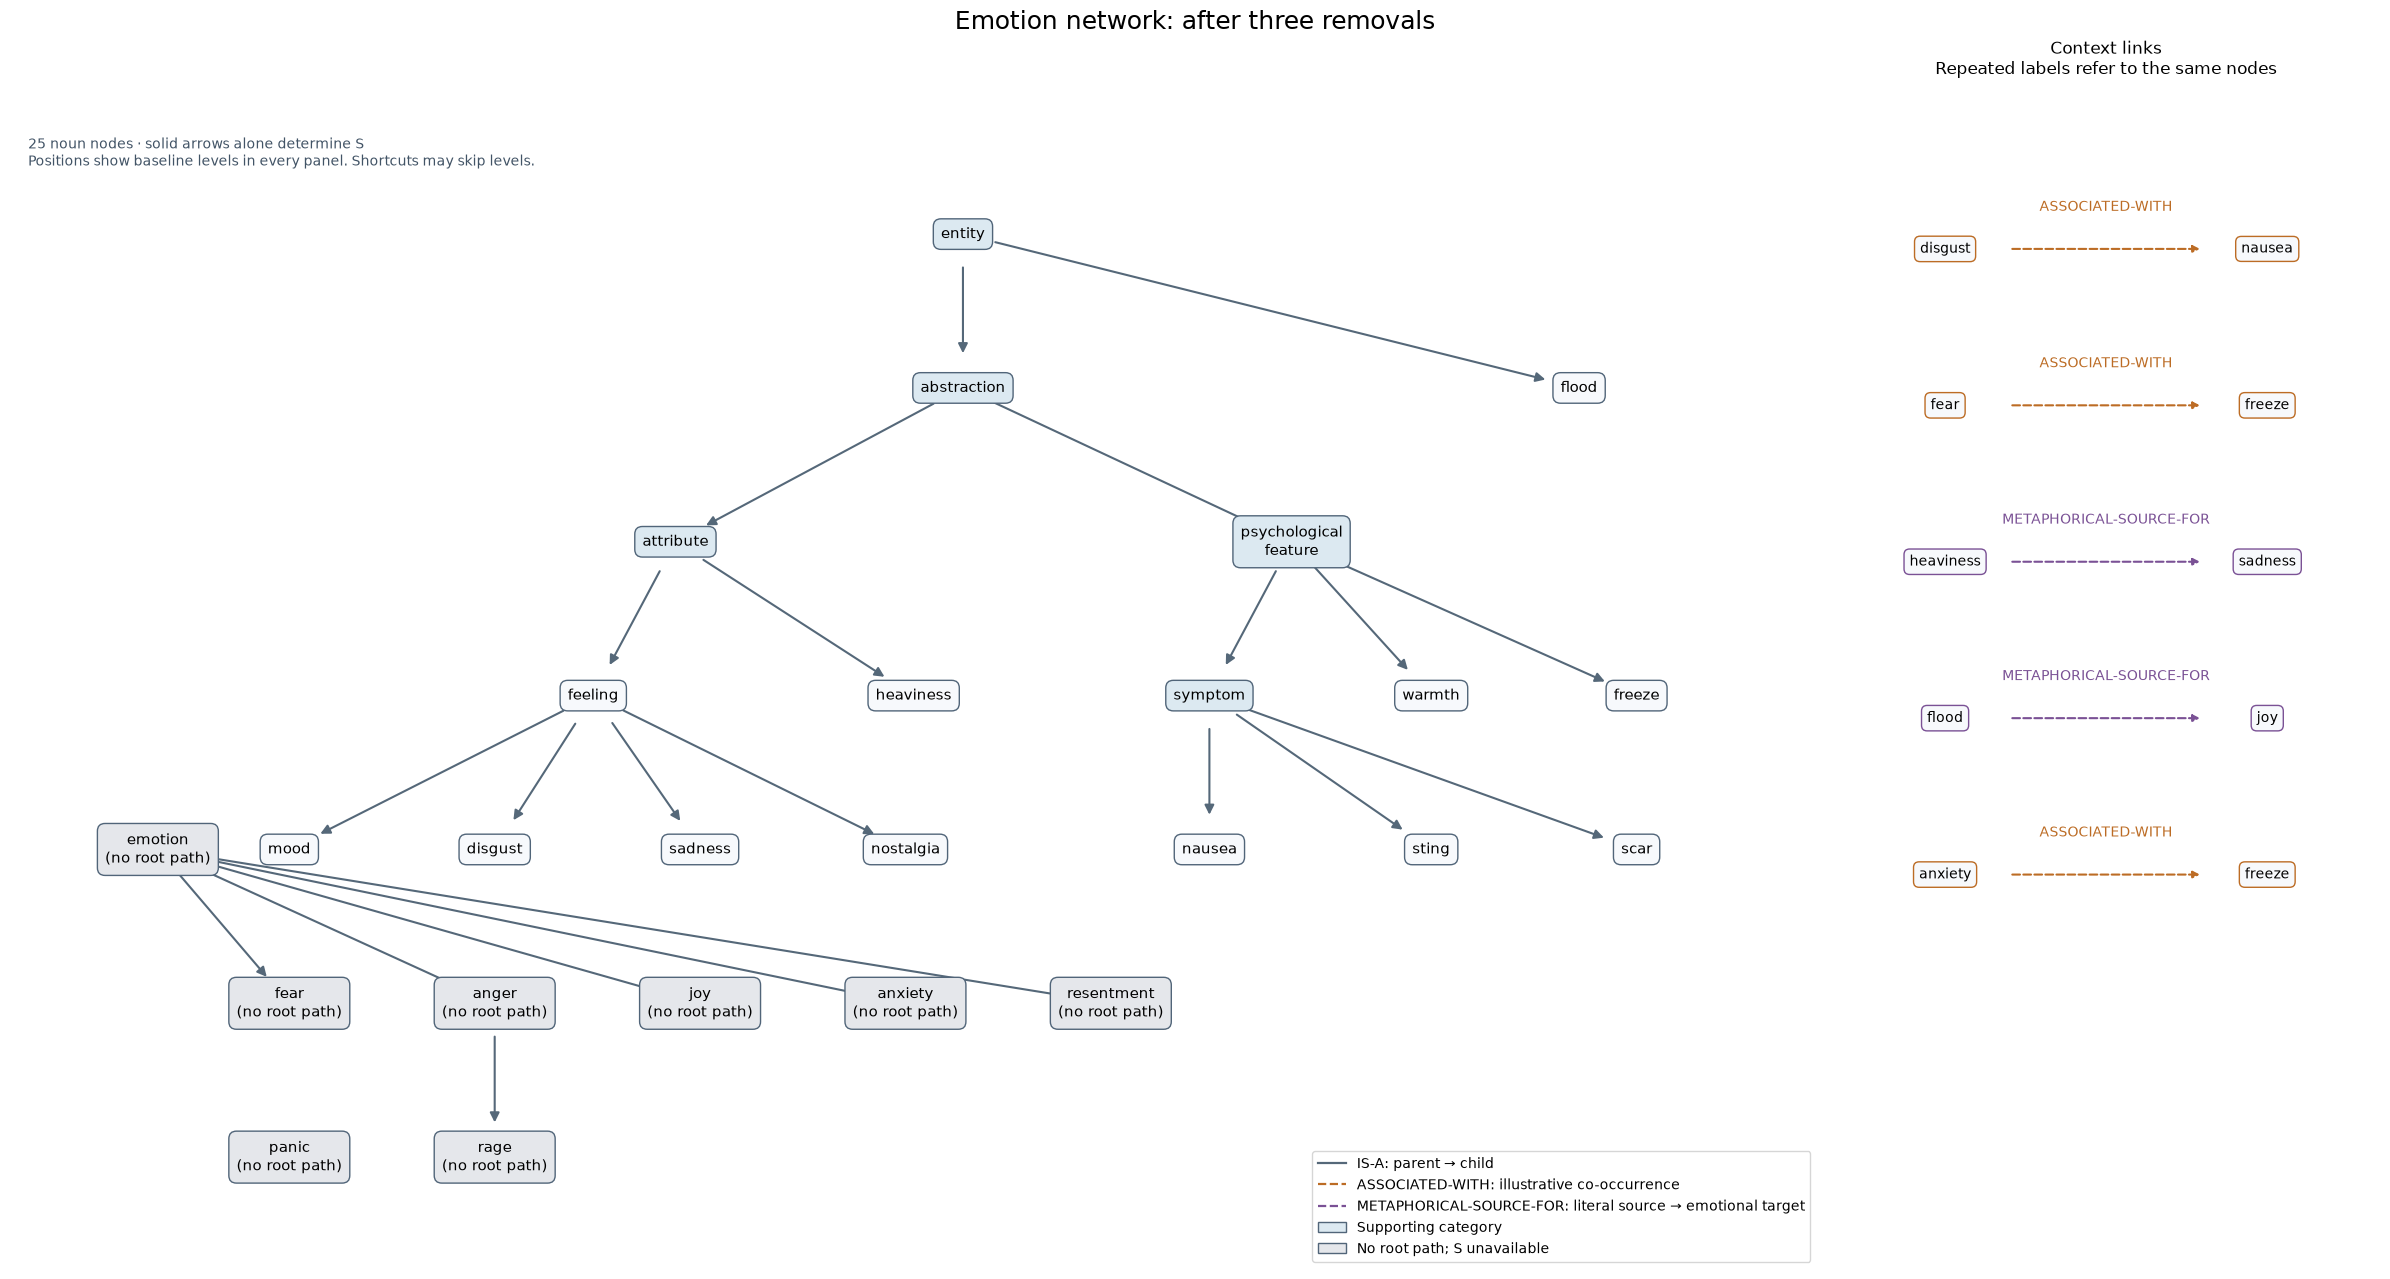

In [17]:
# Reuse the baseline positions to make changed edges and disconnections comparable.
draw_network(
    added_edges, results_dir / 'network_added.png', 'Emotion network: after three additions'
)
draw_network(
    removed_edges, results_dir / 'network_removed.png', 'Emotion network: after three removals'
)

## Task 4. Compare with the full WordNet taxonomy

HA1 uses full WordNet noun depths. For each shared reachable noun, compare that result with compact edge counts and with distances weighted by the recorded number of WordNet steps. Rank correlation uses average ranks for ties on the common reachable subset. The reference CSV is the term/depth export from the executed HA1 notebook.

In [18]:
reference = pd.read_csv(data_dir / 'ha1_depths.csv').set_index('term')


def weighted_depth(edge_table):
    graph = nx.DiGraph()
    for row in edge_table.query("type == 'is_a'").itertuples():
        graph.add_edge(row.source, row.target, steps=int(row.wordnet_hops))
    return pd.Series(nx.single_source_dijkstra_path_length(graph, ROOT, weight='steps'))


depths = reference.join(baseline.set_index('id')[['depth_min', 'S_depth']])
depths['WordNet_steps'] = weighted_depth(edges)
valid = depths.dropna()
assert np.array_equal(valid.S_raw, valid.WordNet_steps)
rho = valid.S_raw.rank().corr(valid.depth_min.rank())
print(f'Shared reachable nouns: {len(valid)}. Spearman rho: {rho:.3f}')
print(
    'Panic, weighted steps before and after the shortcut:',
    weighted_depth(edges)['panic'],
    weighted_depth(added_edges)['panic'],
)
depths.to_csv(results_dir / 'depth_comparison.csv')
display(depths)

,S_raw,S_norm,depth_min,S_depth,WordNet_steps
term,,,,,
emotion,5.0,0.2,4.0,0.666667,5.0
feeling,4.0,0.0,3.0,0.500000,4.0
mood,5.0,0.2,4.0,0.666667,5.0
fear,6.0,0.4,5.0,0.833333,6.0
anger,6.0,0.4,5.0,0.833333,6.0
disgust,6.0,0.4,4.0,0.666667,6.0
joy,6.0,0.4,5.0,0.833333,6.0
sadness,5.0,0.2,4.0,0.666667,5.0
panic,7.0,0.6,6.0,1.000000,7.0


In [19]:
single_removals = []
for row in remove_rows.itertuples():
    mask = (
        added_edges.source.eq(row.source)
        & added_edges.target.eq(row.target)
        & added_edges.type.eq(row.type)
    )
    table = specificity_table(added_edges.loc[~mask]).set_index('id')
    single_removals.append(
        {
            'removed': f'{row.source} → {row.target}',
            'reachable': int(table.reachable.sum()),
            'max_depth': table.depth_min.max(),
            'panic_depth': table.loc['panic', 'depth_min'],
        }
    )
single_removals = pd.DataFrame(single_removals)
single_removals.to_csv(results_dir / 'single_removals.csv', index=False)
display(single_removals)

,removed,reachable,max_depth,panic_depth
0,fear → panic,25,6.0,5.0
1,feeling → emotion,17,4.0,NaN
2,emotion → panic,25,6.0,6.0


### Expand a compact leaf

Expand flood with every direct noun hyponym in the bundled WordNet version. This separate coverage test keeps the submitted perturbation stages intact. Each new edge is identified by its source and target synset.

In [20]:
expanded = baseline_taxonomy.copy()
expansion = []
for offset, parents in wordnet_parents.items():
    if offsets['flood'] in parents:
        child = 'wn30-' + offset + '-n'
        expanded.add_edge('flood', child)
        expansion.append(
            {
                'source': 'flood',
                'source_synset': offsets['flood'],
                'child_synset': child,
                'child_lemma': wordnet_lemmas[offset][0],
                'relation': 'is_a',
                'provenance': 'wordnet',
            }
        )
expansion = pd.DataFrame(expansion)
expansion.to_csv(results_dir / 'flood_hyponyms.csv', index=False)
display(expansion)
count = len(nx.descendants(expanded, 'flood'))
max_count = len(nx.descendants(expanded, ROOT))
expanded_score = 1 - np.log1p(count) / np.log1p(max_count)
original = baseline[baseline.id.isin(ha0.term) & baseline.reachable]
print(
    f'Baseline breadth ceiling: {original.S_breadth.eq(1).sum()}/{len(original)} original reachable concepts.'
)
print(f'Flood, after adding {count} direct hyponyms: S_breadth = {expanded_score:.3f}.')

,source,source_synset,child_synset,child_lemma,relation,provenance
0,flood,11454591,wn30-11454953-n,debacle,is_a,wordnet
1,flood,11454591,wn30-11455092-n,flash_flood,is_a,wordnet
2,flood,11454591,wn30-11455386-n,Noah's_flood,is_a,wordnet


### Results and exit ticket

The [300-word interpretation](interpretation.md) discusses the observed changes and limitations. In this graph, panic is more specific than emotion by depth because it is reached through fear. Replacing that route with a broader parent changes the estimate. Bodily responses and metaphorical uses appear only as typed examples; the graph itself does not model perception or emotional experience.